In [2]:
import os
os.getcwd()
#os.chdir("write your own path")

'/content'

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# importing dataset
df = pd.read_csv("/content/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0


In [5]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
764,10,101,76,48,180,32.9,0.171,63,0
765,2,122,70,27,0,36.8,0.340,27,0
766,5,121,72,23,112,26.2,0.245,30,0
767,1,126,60,0,0,30.1,0.349,47,1
768,1,93,70,31,0,30.4,0.315,23,0


In [6]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0
...,...,...,...,...,...,...,...,...,...
764,10,101,76,48,180,32.9,0.171,63,0
765,2,122,70,27,0,36.8,0.340,27,0
766,5,121,72,23,112,26.2,0.245,30,0
767,1,126,60,0,0,30.1,0.349,47,1


# Exploratory Data Analysis - EDA Part (check the dataset end to end)


In [7]:
# import dtale package for EDA purpose
#!pip install dtale

In [8]:
#import dtale
#dtale.show(df)

# Cleaning/Preprocessing part

1) Handles Duplicates
2) Handling Missing data
3) Handling Encoding (Char to Num)
4) Handling Outlier
5) Feature Scaling part
6) Handling Imbalance dataset (this is only applicable on classification problem)

In [9]:
# part 1 - Duplicates data treatment
df.duplicated().sum()

1

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df.duplicated().sum()

0

In [12]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0
5,0,137,40,35,168,43.1,2.288,33,1


In [13]:
# Information of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 768 entries, 0 to 768
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 60.0 KB


In [14]:
df['Glucose'].min()

0

In [15]:
# part 2  - missing data
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [16]:
df.isnull().sum().sum()

0

In [17]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [18]:
df['Pregnancies'].min()

0

In [19]:
df['Glucose'].min() # problem

0

In [20]:
df['Glucose'].mean()

120.89453125

In [21]:
print(df['BloodPressure'].min()) # problem
print("******************")
print(df['SkinThickness'].min()) # problem
print("******************")
print(df['Insulin'].min()) # problem
print("******************")
print(df['BMI'].min()) # problem
print("******************")
print(df['DiabetesPedigreeFunction'].min())
print("******************")
print(df['Age'].min())

0
******************
0
******************
0
******************
0.0
******************
0.078
******************
21


In [22]:
# use np.where condition - check with your business (min threshold value) '40'
df['Glucose'] = np.where(df['Glucose'] == 0, 40, df['Glucose'] )

In [23]:
df['Glucose'].min()

40

In [24]:
df['BloodPressure'] = np.where(df['BloodPressure'] == 0, df['BloodPressure'].mean(), df['BloodPressure'] )
df['SkinThickness'] = np.where(df['SkinThickness'] == 0, df['SkinThickness'].mean(), df['SkinThickness'] )
df['Insulin'] = np.where(df['Insulin'] == 0, df['Insulin'].mean(), df['Insulin'] )
df['BMI'] = np.where(df['BMI'] == 0, df['BMI'].mean(), df['BMI'] )

In [25]:
print(df['Glucose'].min()) # problem
print("******************")
print(df['BloodPressure'].min()) # problem
print("******************")
print(df['SkinThickness'].min()) # problem
print("******************")
print(df['Insulin'].min()) # problem
print("******************")
print(df['BMI'].min()) # problem
print("******************")
print(df['DiabetesPedigreeFunction'].min())
print("******************")
print(df['Age'].min())

40
******************
24.0
******************
7.0
******************
14.0
******************
18.2
******************
0.078
******************
21


# There is no encoding required here because there is no char variable avaialble

<Axes: ylabel='Glucose'>

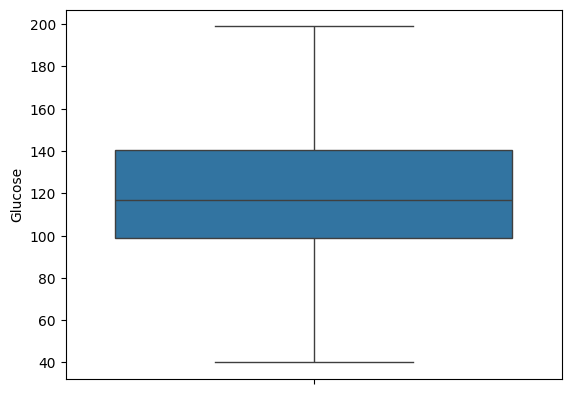

In [26]:
# Outlier part
sns.boxplot(y='Glucose', data=df)

<Axes: ylabel='Age'>

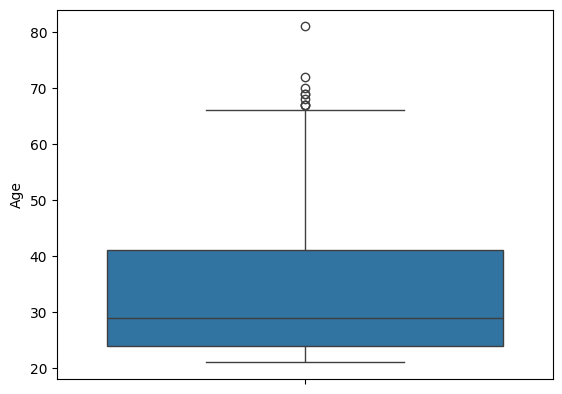

In [27]:
sns.boxplot(y='Age', data=df)

In [28]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.154948,72.254807,26.606479,118.660163,32.450805,0.471876,33.240885,0.348958
std,3.369578,31.137801,12.115932,9.631241,93.080358,6.875374,0.331329,11.760232,0.476951
min,0.000000,40.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,20.536458,79.799479,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,79.799479,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [29]:
# Check imbalance dataset
df['Outcome'].value_counts(normalize=True)

,proportion
Outcome,
0,0.651042
1,0.348958


In [30]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35.000000,79.799479,33.6,0.627,50,1
2,1,85,66.0,29.000000,79.799479,26.6,0.351,31,0
3,8,183,64.0,20.536458,79.799479,23.3,0.672,32,1
4,1,89,66.0,23.000000,94.000000,28.1,0.167,21,0
5,0,137,40.0,35.000000,168.000000,43.1,2.288,33,1


In [31]:
df.shape

(768, 9)

In [32]:
# split the data into dep and ind variable
x = df.iloc[:,:-1]
x.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72.0,35.000000,79.799479,33.6,0.627,50
2,1,85,66.0,29.000000,79.799479,26.6,0.351,31
3,8,183,64.0,20.536458,79.799479,23.3,0.672,32
4,1,89,66.0,23.000000,94.000000,28.1,0.167,21
5,0,137,40.0,35.000000,168.000000,43.1,2.288,33


In [33]:
y = df.iloc[:,-1]
y.head()

,Outcome
0,1
2,0
3,1
4,0
5,1


In [34]:
y.value_counts()

,count
Outcome,
0,500
1,268


In [35]:
768*70/100

537.6

In [36]:
# split the data for training and testing purpose
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.3, random_state=123, stratify=y)

In [37]:
x_test

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
553,6,114,88.000000,20.536458,79.799479,27.8,0.247,66
439,1,97,70.000000,15.000000,79.799479,18.2,0.147,21
150,2,90,70.000000,17.000000,79.799479,27.3,0.085,22
374,2,105,58.000000,40.000000,94.000000,34.9,0.225,25
37,11,138,76.000000,20.536458,79.799479,33.2,0.420,35
...,...,...,...,...,...,...,...,...
86,2,110,74.000000,29.000000,125.000000,32.4,0.698,27
8,10,115,69.105469,20.536458,79.799479,35.3,0.134,29
299,14,100,78.000000,25.000000,184.000000,36.6,0.412,46
342,1,95,74.000000,21.000000,73.000000,25.9,0.673,36


In [38]:
y_test

,Outcome
553,0
439,0
150,0
374,0
37,0
...,...
86,0
8,0
299,1
342,0


In [39]:
print(y_train.value_counts())
print("**********************")
print(y_test.value_counts())

Outcome
0    350
1    187
Name: count, dtype: int64
**********************
Outcome
0    150
1     81
Name: count, dtype: int64


# Building Traditional Algorithm - Machine Learning

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

In [41]:
# Evaluation Matrix
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

       Method Used  Accuracy
0  LogitRegression  0.748918
1            Dtree  0.692641
2               RF  0.770563
3              XGB  0.744589
4              SVM  0.727273
5              NBT  0.766234
6              KNN  0.679654
7           Voting  0.770563
Axes(0.125,0.11;0.775x0.77)


/tmp/ipython-input-42-732164885.py:64: UserWarning: FixedFormatter should only be used together with FixedLocator
  chart.set_xticklabels(chart.get_xticklabels(), rotation=90)


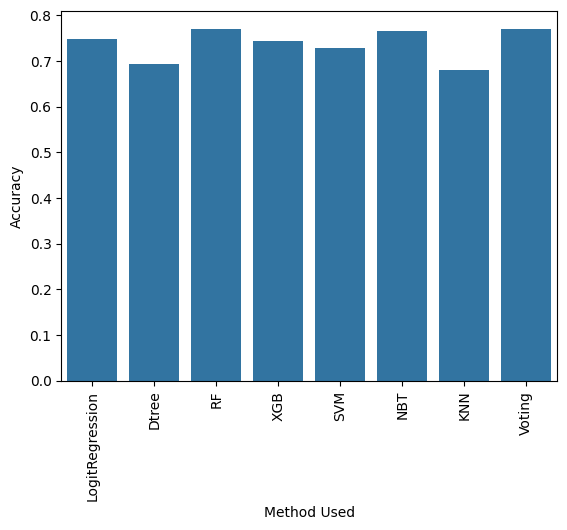

In [42]:
list_met = []
list_accuracy=[]

# logistic regression
logit = LogisticRegression()
logit = logit.fit(x_train, y_train)
y_pred_lr = logit.predict(x_test)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

# DecisionTreeClassifier
dtree = DecisionTreeClassifier()
dtree = dtree.fit(x_train, y_train)
y_pred_dt = dtree.predict(x_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

# RandomForestClassifier
rforest = RandomForestClassifier(random_state=123)
rforest = rforest.fit(x_train, y_train)
y_pred_rf = rforest.predict(x_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

# XGBClassifier
xgboost = XGBClassifier(random_state=123)
xgboost = xgboost.fit(x_train, y_train)
y_pred_xg = xgboost.predict(x_test)
accuracy_xg = accuracy_score(y_test, y_pred_xg)

# SVC
svm = SVC()
svm = svm.fit(x_train, y_train)
y_pred_svm = svm.predict(x_test)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

# GaussianNB
nbt = GaussianNB()
nbt = nbt.fit(x_train, y_train)
y_pred_nbt = nbt.predict(x_test)
accuracy_nbt = accuracy_score(y_test, y_pred_nbt)

# KNeighborsClassifier
knn = KNeighborsClassifier()
knn = knn.fit(x_train, y_train)
y_pred_knn = knn.predict(x_test)
accuracy_knn = accuracy_score(y_test, y_pred_knn)

# VotingClassifier
model_evc = VotingClassifier(estimators = [('logit', logit), ('dtree', dtree),('rforest', rforest), ('xgboost',xgboost),
                                           ('svm',svm),('nbt',nbt),('knn',knn)])

model_evc = model_evc.fit(x_train, y_train)
y_pred_evc = model_evc.predict(x_test)
accuracy_evc = accuracy_score(y_test, y_pred_evc)


list1 = ['LogitRegression','Dtree','RF','XGB','SVM', 'NBT', 'KNN', 'Voting']
list2 = [accuracy_lr,accuracy_dt,accuracy_rf,accuracy_xg,accuracy_svm,accuracy_nbt,accuracy_knn,accuracy_evc]
list = [logit,dtree,rforest,xgboost,svm, nbt, knn, model_evc]

df_accuracy = pd.DataFrame({"Method Used": list1, "Accuracy":list2})
print(df_accuracy)


chart = sns.barplot(x="Method Used", y="Accuracy", data=df_accuracy)
chart.set_xticklabels(chart.get_xticklabels(), rotation=90)
print(chart)

In [43]:
y_pred_lr

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0])

In [44]:
y_test

,Outcome
553,0
439,0
150,0
374,0
37,0
...,...
86,0
8,0
299,1
342,0


# Automation Method to build Machine Learning Problem - 'Pycaret'

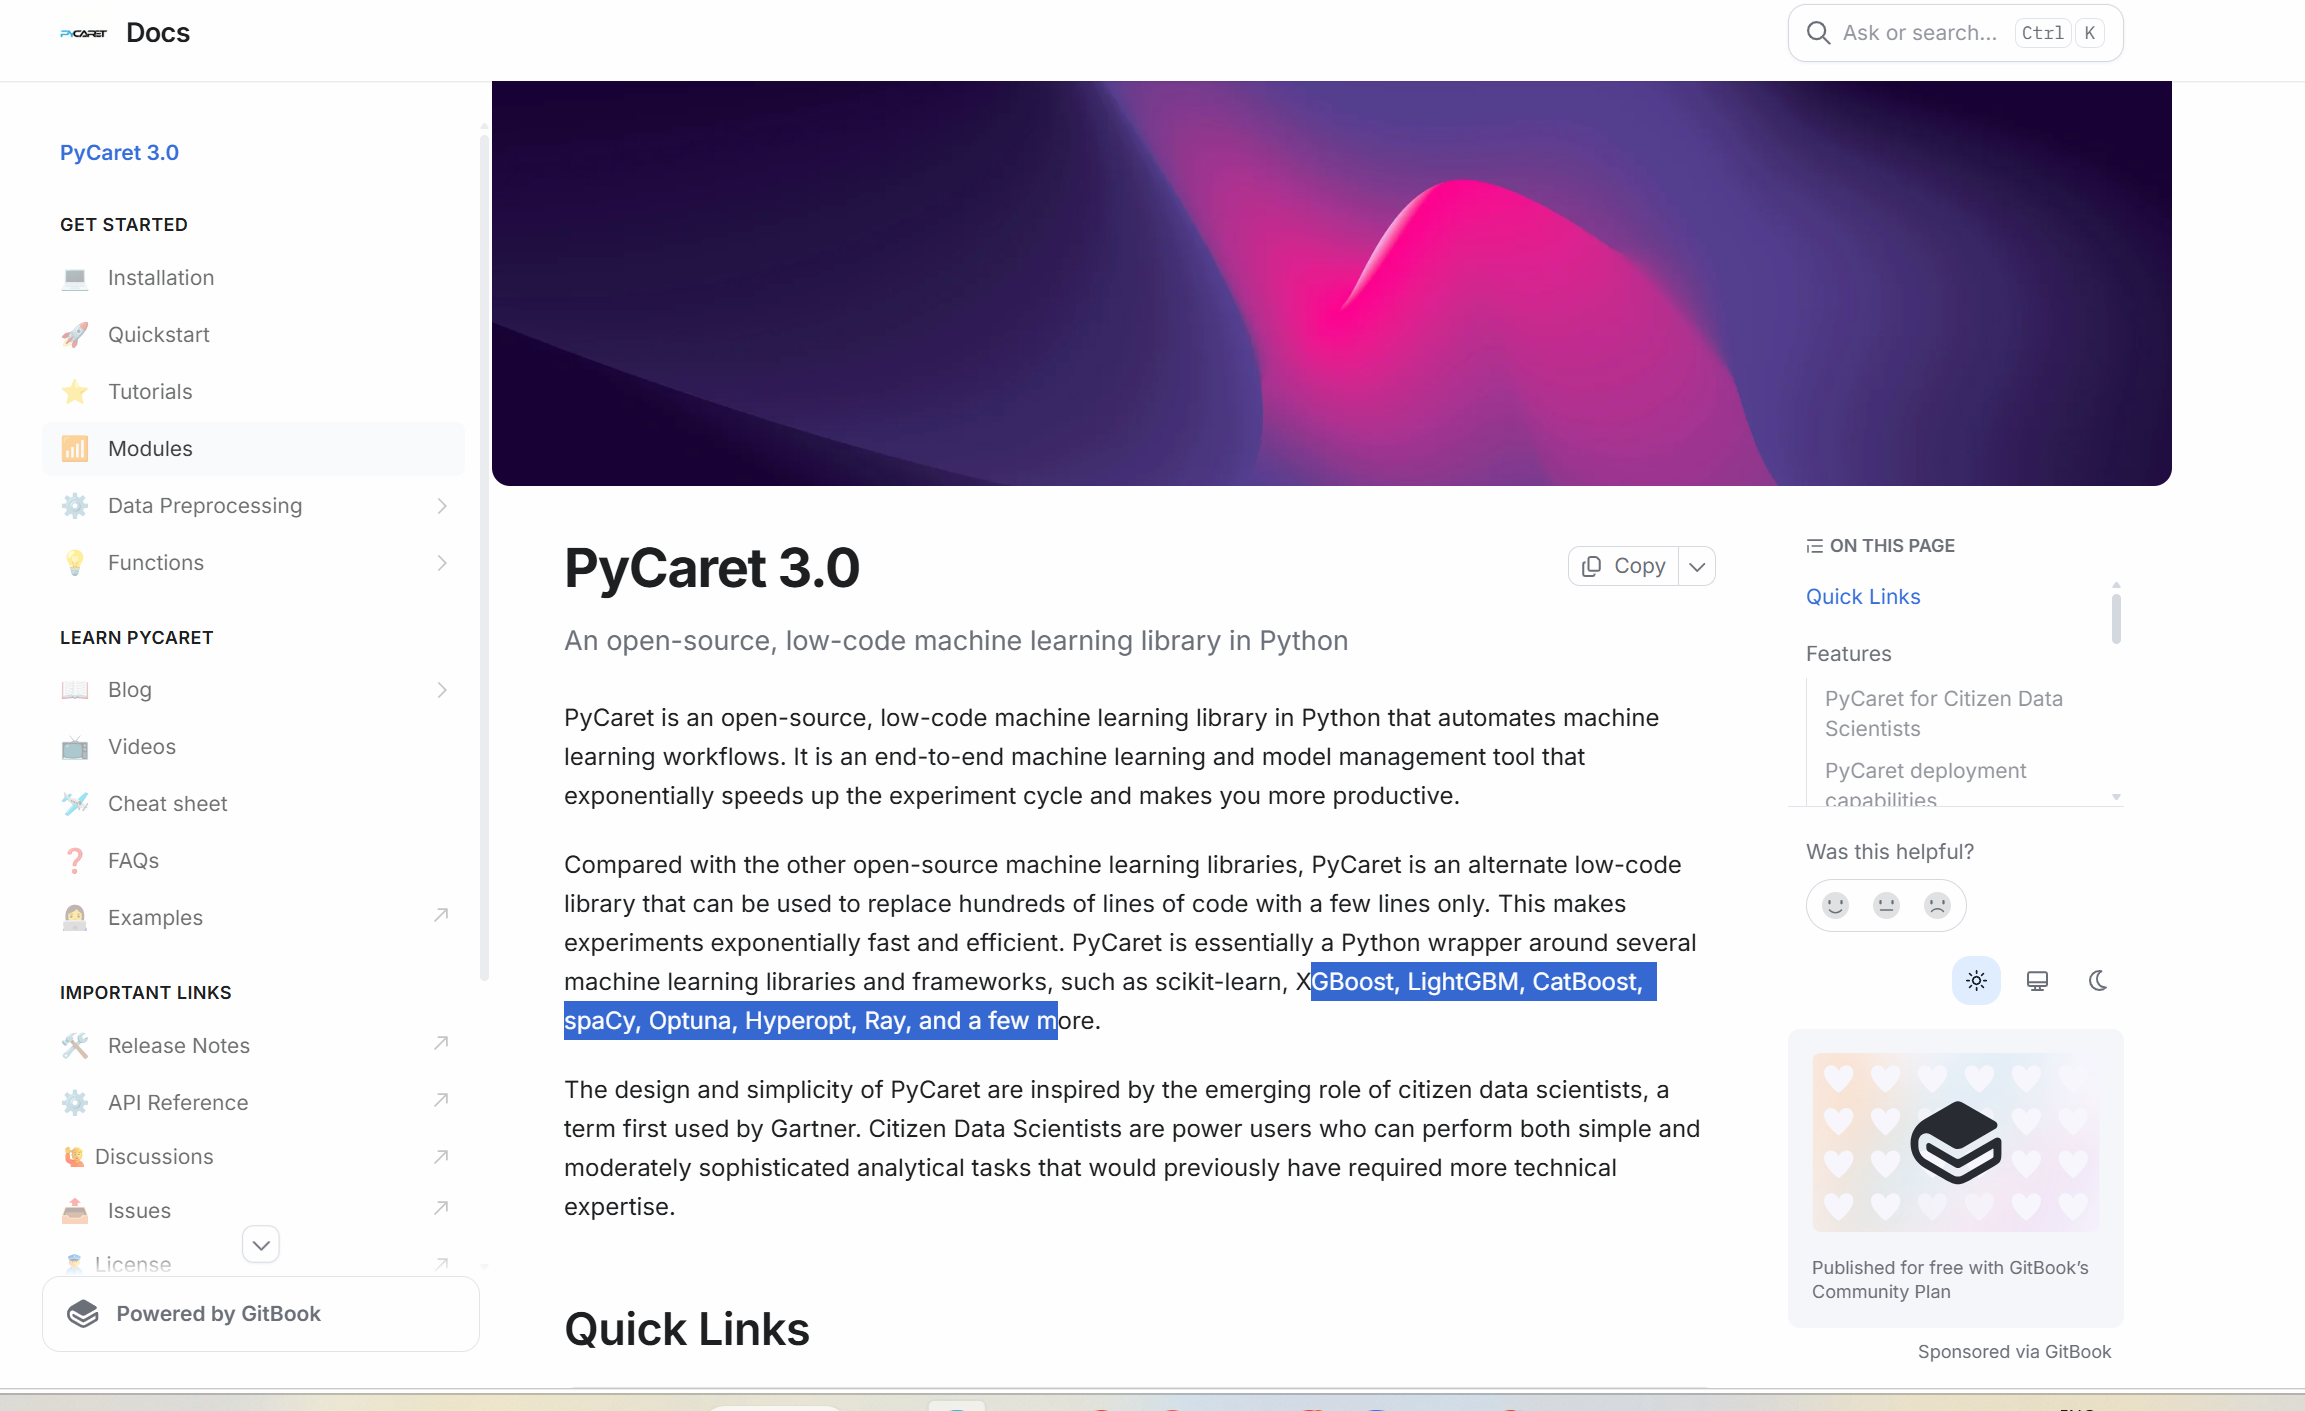

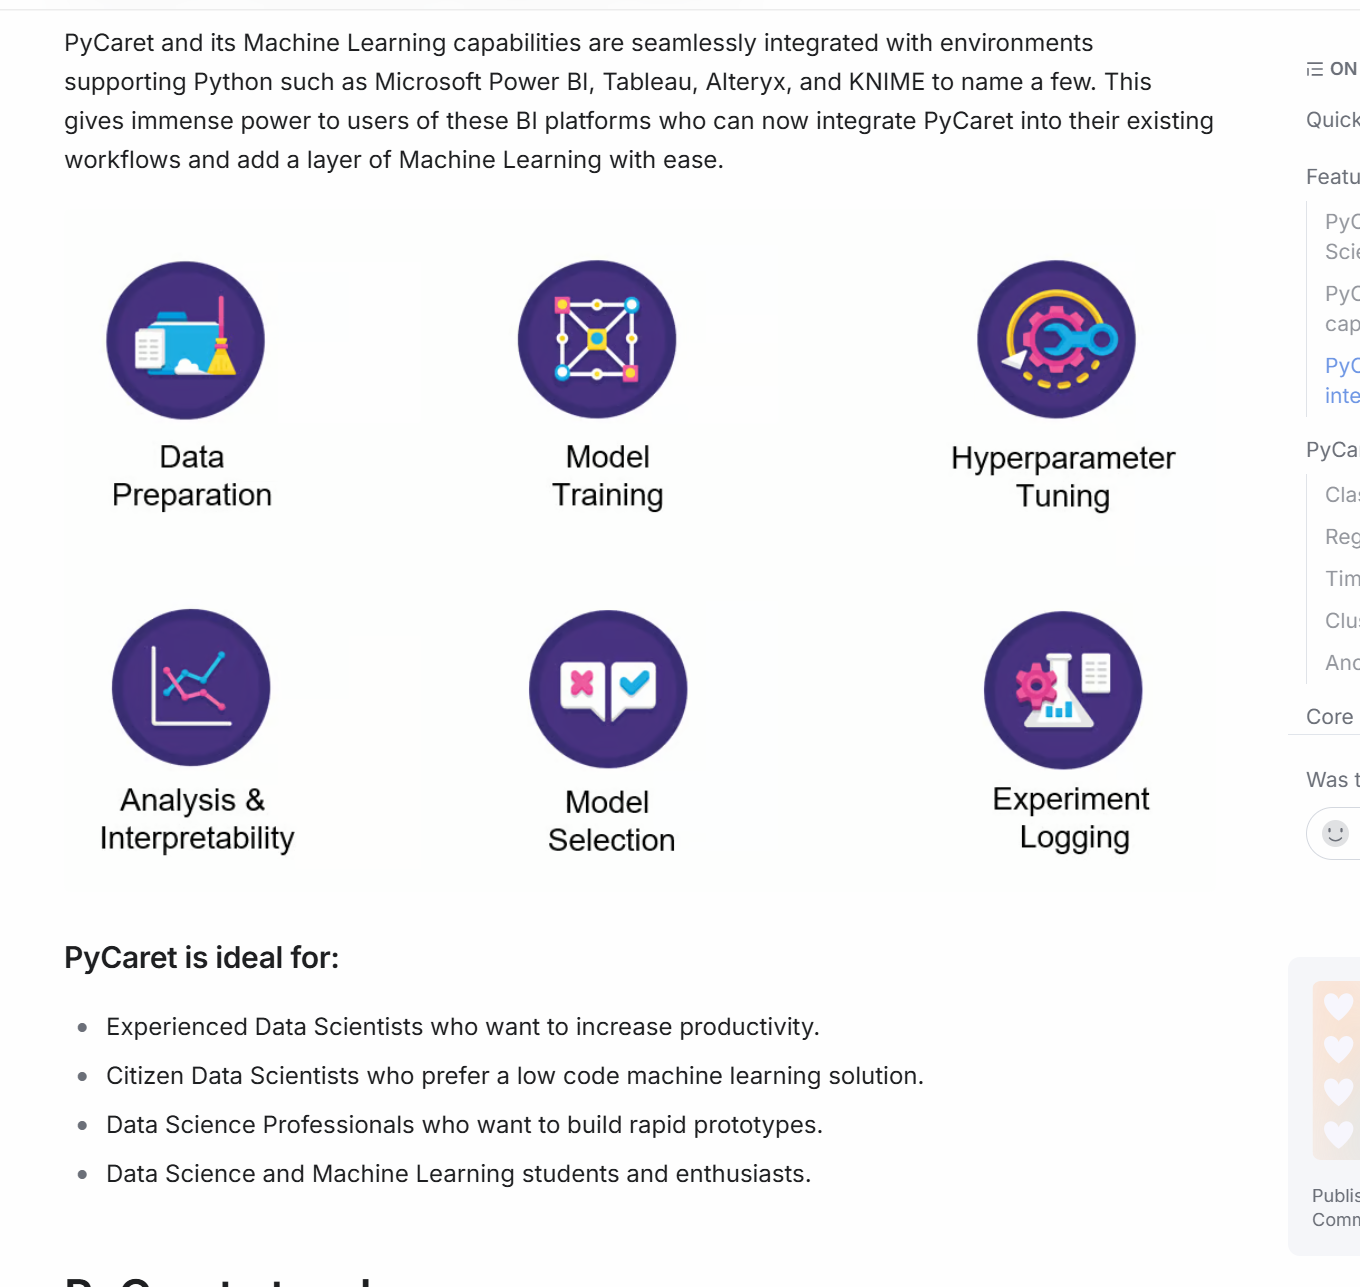

In [45]:
#!pip install pycaret

In [46]:
from pycaret.classification import *

In [47]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35.000000,79.799479,33.6,0.627,50,1
2,1,85,66.0,29.000000,79.799479,26.6,0.351,31,0
3,8,183,64.0,20.536458,79.799479,23.3,0.672,32,1
4,1,89,66.0,23.000000,94.000000,28.1,0.167,21,0
5,0,137,40.0,35.000000,168.000000,43.1,2.288,33,1


In [53]:
training_dataset = df.sample(frac=0.7,random_state=123).reset_index(drop=True)
test_dataset = df.sample(frac=0.3,random_state=123).reset_index(drop=True)

In [49]:
training_dataset.shape

(538, 9)

In [54]:
test_dataset.shape

(230, 9)

In [55]:
# step 1 - setup
classification_model = setup(data=training_dataset, target='Outcome', session_id=123)

,Description,Value
0,Session id,123
1,Target,Outcome
2,Target type,Binary
3,Original data shape,"(538, 9)"
4,Transformed data shape,"(538, 9)"
5,Transformed train set shape,"(376, 9)"
6,Transformed test set shape,"(162, 9)"
7,Numeric features,8
8,Preprocess,True
9,Imputation type,simple


In [56]:
# step 2 - compare model

compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
lr,Logistic Regression,0.7451,0.8064,0.5192,0.6930,0.5876,0.4099,0.4226,0.6690
ridge,Ridge Classifier,0.7425,0.8068,0.5038,0.6970,0.5783,0.4007,0.4157,0.0200
lda,Linear Discriminant Analysis,0.7398,0.8065,0.5038,0.6851,0.5757,0.3953,0.4080,0.0200
et,Extra Trees Classifier,0.7394,0.7730,0.5544,0.6666,0.5991,0.4093,0.4177,0.1420
qda,Quadratic Discriminant Analysis,0.7233,0.7639,0.5121,0.6413,0.5591,0.3648,0.3761,0.0290
gbc,Gradient Boosting Classifier,0.7180,0.7694,0.5319,0.6069,0.5610,0.3574,0.3624,0.1190
rf,Random Forest Classifier,0.7154,0.7721,0.4929,0.6229,0.5432,0.3426,0.3519,0.3400
nb,Naive Bayes,0.7076,0.7711,0.5044,0.6225,0.5429,0.3351,0.3481,0.0210
ada,Ada Boost Classifier,0.7023,0.7716,0.5473,0.5871,0.5628,0.3387,0.3416,0.0940
xgboost,Extreme Gradient Boosting,0.6756,0.7415,0.5236,0.5457,0.5274,0.2827,0.2877,0.0960


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/pycaret/internal/pycaret_experiment/supervised_experiment.py:339: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(highlight_cols, subset=["TT (Sec)"])


LogisticRegression(C=1.0, class_weight=None, dual=False, fit_intercept=True,
                   intercept_scaling=1, l1_ratio=None, max_iter=1000,
                   multi_class='auto', n_jobs=None, penalty='l2',
                   random_state=123, solver='lbfgs', tol=0.0001, verbose=0,
                   warm_start=False)

In [57]:
# Step 3 - Choose best model
best_model = create_model('lr')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7105,0.7046,0.6154,0.5714,0.5926,0.3686,0.3692
1,0.6842,0.7231,0.4615,0.5455,0.5000,0.2716,0.2736
2,0.7105,0.7938,0.4615,0.6000,0.5217,0.3192,0.3249
3,0.7632,0.8571,0.5000,0.7778,0.6087,0.4502,0.4728
4,0.8158,0.8631,0.6429,0.8182,0.7200,0.5857,0.5951
5,0.6316,0.7500,0.3571,0.5000,0.4167,0.1582,0.1630
6,0.8378,0.9071,0.6923,0.8182,0.7500,0.6312,0.6361
7,0.7838,0.8494,0.6154,0.7273,0.6667,0.5083,0.5122
8,0.7297,0.7724,0.3846,0.7143,0.5000,0.3369,0.3672


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

In [58]:
# Step 4 - Fine Tuing
tuned_model = tune_model(best_model)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.6842,0.7046,0.5385,0.5385,0.5385,0.2985,0.2985
1,0.6842,0.7262,0.4615,0.5455,0.5000,0.2716,0.2736
2,0.7105,0.7908,0.4615,0.6000,0.5217,0.3192,0.3249
3,0.7368,0.8571,0.4286,0.7500,0.5455,0.3791,0.4085
4,0.8158,0.8661,0.6429,0.8182,0.7200,0.5857,0.5951
5,0.6316,0.7500,0.3571,0.5000,0.4167,0.1582,0.1630
6,0.8378,0.9038,0.6923,0.8182,0.7500,0.6312,0.6361
7,0.7838,0.8526,0.6154,0.7273,0.6667,0.5083,0.5122
8,0.7297,0.7692,0.3846,0.7143,0.5000,0.3369,0.3672


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 10 folds for each of 10 candidates, totalling 100 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


In [59]:
# step 5 - evaluation metrix

evaluate_model(best_model)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

In [60]:
# Step 6 - Prediction
unseen_dataset = predict_model(best_model, test_dataset)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Logistic Regression,0.7826,0.8625,0.6364,0.7568,0.6914,0.5255,0.5302


In [61]:
# Step 7- save the model for deployment
save_model(best_model, 'best_model')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Pregnancies', 'Glucose',
                                              'BloodPressure', 'SkinThickness',
                                              'Insulin', 'BMI',
                                              'DiabetesPedigreeFunction',
                                              'Age'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=None,
                                                               keep_empty_features=False,
                                                               missing_values=nan,
                                                               strategy='mean'))),
                 (...
          